# Hospital Stay Duration Model

Predicts how long a patient is likely to stay in hospital - grouped into 3 buckets (0-1 days,
2-3 days, 4+ days) - using only information available at arrival, the same timing constraint as
the severity and transfer probability models.

**Why buckets, not exact days:** the raw day count is heavily skewed (median 1 day, a handful of
patients stay 2+ weeks) - a regression would be dominated by trying to fit that long tail. Buckets
were chosen from the actual distribution, not copied from last year's undocumented boundaries.
Started as 4 groups (0 days, 1 day, 2-3 days, 4+ days), then merged to 3 (0-1 days 66.7%,
2-3 days 25.6%, 4+ days 7.7%) once it was clear 0 and 1 day were the hardest to tell apart and
mean the same thing practically (early discharge) - decided before evaluating model performance,
not in response to weak results.

**Also checked: whether pairs of the surviving features carry more signal together than either
does alone** (Section 4b) - tested with the same statistical rigor as every individual feature,
not just tried and kept on intuition.

**`severity_label` / `composite` cannot be used as features here - this is the most direct leakage
risk in this project so far.** The severity label's length-of-stay component *is* `total_days`,
the exact number this model buckets and predicts. Using severity to predict stay duration would be
close to predicting the target from itself. Loaded from `Preprocessed Dataset.csv` (before the
severity label existed) to make this structurally impossible, same as the discharge outcome and
transfer probability notebooks.

**Also excluded, same reasoning as every other model here:**
- `Type of injury No 1` - several categories are diagnostic conclusions needing imaging, not known
  at arrival.
- `Investigation Done`, `Current Hospital Name` - last year's version used both. Investigation is
  post-arrival treatment information; hospital name risks learning "which hospital" instead of
  genuine clinical signal.
- Financial/social fields, `Ethnicity` - same principle applied throughout this project.
- Last year's model also had an undocumented, hand-rolled severity score buried in the serving
  code (`fracture=3, amputation=4, spinal=4...`) - invented independently of any real severity
  model and never validated. Not reused here.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (recall_score, precision_score, f1_score, make_scorer,
                              classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.base import clone

from catboost import CatBoostClassifier, Pool
import xgboost as xgb
import lightgbm as lgb
import shap
import matplotlib.pyplot as plt
import joblib, json, os

RANDOM_STATE = 42
os.makedirs("artifacts", exist_ok=True)

## 1. Build the target: bucket total_days into 4 stay-duration groups

Same ward-day combination logic used in every notebook that's touched length of stay: three
mostly-empty ward-day columns combined into one number, with `min_count=1` so a genuinely
unrecorded stay becomes missing, not a silent 0. In this dataset it turns out every patient has a
resolvable `total_days` (0 missing), because the first ward's value is always either a real number
or a confirmed 0 from early discharge.

In [2]:
ward_cols = ['Number of days in first ward', 'Number of days in Second ward', 'Number of days in Third ward']
df = pd.read_csv('Preprocessed Dataset.csv')
for c in ward_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce')
    early_mask = df[c + '_missing_reason'] == 'early_discharge'
    df.loc[early_mask, c] = df.loc[early_mask, c].fillna(0)

df['total_days'] = df[ward_cols].sum(axis=1, skipna=True, min_count=1)
print("Missing total_days:", df['total_days'].isna().sum())

# merged from 4 buckets to 3: '0 days' and '1 day' were the two hardest to tell apart
# with arrival-time-only signal, and both mean the same thing practically (early discharge) -
# this is a principled simplification decided before looking at model performance, not a
# response to weak results after the fact
def bucket_stay(days):
    if days <= 1:
        return '0-1 days'
    elif days <= 3:
        return '2-3 days'
    else:
        return '4+ days'

TARGET = 'stay_duration_bucket'
df[TARGET] = df['total_days'].apply(bucket_stay)
df[TARGET].value_counts(normalize=True).round(3)

Missing total_days: 0


stay_duration_bucket
0-1 days    0.667
2-3 days    0.256
4+ days     0.077
Name: proportion, dtype: float64

## 2. Set the candidate feature list

Only fields a nurse could realistically know within the first few minutes of a patient's arrival -
demographics, accident circumstances, and initial injury location. Narrowed down by the
statistical check in Section 4.

In [3]:
CANDIDATE_FEATURES = [
    'Age', 'Gender',
    'Mode of Transport to the Hospital', 'Time Taken To Reach Hospital',
    'Vehicle Type', 'Helmet Worn', 'Collision With ',
    'Approximate Speed', 'Road Type', 'Road Condition', 'Visiblity',
    'Road Signals Exist', 'Collision Force From',
    'Alcohol Consumption', 'Illicit Drugs',
    'Site of Injury No1',
]
df = df.rename(columns={'Collision With ': 'Collision With'})
CANDIDATE_FEATURES = [c if c != 'Collision With ' else 'Collision With' for c in CANDIDATE_FEATURES]
print(df.shape)

(6178, 134)


## 3. Split into training and test data, first

80/20 split, stratified on the stay-duration bucket, before anything else touches the data. The
test set is not opened again until Section 10.

In [4]:
X = df[CANDIDATE_FEATURES].copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True))
print("\nTest class balance:\n", y_test.value_counts(normalize=True))

Train: (4942, 16)  Test: (1236, 16)

Train class balance:
 stay_duration_bucket
0-1 days    0.666936
2-3 days    0.255969
4+ days     0.077094
Name: proportion, dtype: float64

Test class balance:
 stay_duration_bucket
0-1 days    0.666667
2-3 days    0.256472
4+ days     0.076861
Name: proportion, dtype: float64


## 4. Check the candidate features actually matter - training data only

`Age` and `Time Taken To Reach Hospital` are ordered, checked with a test for whether the ordering
itself relates to stay duration. Everything else is a plain category, checked with a test for
whether the stay-duration mix genuinely differs by category, plus a strength score from 0 to 1 so
a technically-real but tiny relationship isn't treated the same as a strong one.

In [5]:
AGE_ORDER = ['1-9','10-19','20-29','30-39','40-49','50-59','60-69','70-79','80-89','90-100']
TIME_ORDER = ['less than 15 minutes','15 minutes - 30 minutes','30 minutes - 1 hour',
              '1 hour - 2 hour','more than 2 hour']

ORDINAL_FEATURES = ['Age', 'Time Taken To Reach Hospital']
NOMINAL_FEATURES = [c for c in CANDIDATE_FEATURES if c not in ORDINAL_FEATURES]

val_df = X_train.copy()
val_df[TARGET] = y_train.values

print("--- Age / Time-to-hospital: does the ORDER relate to stay duration? ---")
ordinal_results = {}
for col, order in [('Age', AGE_ORDER), ('Time Taken To Reach Hospital', TIME_ORDER)]:
    mapping = {v: i for i, v in enumerate(order)}
    groups = [g[col].map(mapping).dropna() for _, g in val_df.groupby(TARGET)]
    h, p = stats.kruskal(*groups)
    ordinal_results[col] = {'H': h, 'p': p}
    print(f"{col:35s} H={h:7.2f}  p={p:.4g}")

--- Age / Time-to-hospital: does the ORDER relate to stay duration? ---
Age                                 H=   0.49  p=0.7809
Time Taken To Reach Hospital        H=   7.71  p=0.02121


In [6]:
print("--- Other categories: does the stay-duration mix actually differ by category? ---")
cat_results = {}
for col in NOMINAL_FEATURES:
    ct = pd.crosstab(val_df[col], val_df[TARGET])
    chi2, p, dof, exp = stats.chi2_contingency(ct)
    n = ct.values.sum()
    cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    cat_results[col] = {'chi2': chi2, 'p': p, 'cramers_v': cramers_v}
    flag = "  <-- WEAK/NO SIGNAL -> DROP" if p > 0.05 or cramers_v < 0.05 else ""
    print(f"{col:35s} chi2={chi2:8.2f}  p={p:.4g}  Cramer'sV={cramers_v:.3f}{flag}")

--- Other categories: does the stay-duration mix actually differ by category? ---
Gender                              chi2=    1.48  p=0.4767  Cramer'sV=0.017  <-- WEAK/NO SIGNAL -> DROP
Mode of Transport to the Hospital   chi2=   10.98  p=0.0889  Cramer'sV=0.044  <-- WEAK/NO SIGNAL -> DROP
Vehicle Type                        chi2=    1.79  p=0.4088  Cramer'sV=0.022  <-- WEAK/NO SIGNAL -> DROP
Helmet Worn                         chi2=    0.14  p=0.9343  Cramer'sV=0.007  <-- WEAK/NO SIGNAL -> DROP
Collision With                      chi2=   24.84  p=0.4144  Cramer'sV=0.058  <-- WEAK/NO SIGNAL -> DROP
Approximate Speed                   chi2=   15.33  p=0.01782  Cramer'sV=0.046  <-- WEAK/NO SIGNAL -> DROP
Road Type                           chi2=    2.54  p=0.6383  Cramer'sV=0.018  <-- WEAK/NO SIGNAL -> DROP
Road Condition                      chi2=    4.21  p=0.1219  Cramer'sV=0.033  <-- WEAK/NO SIGNAL -> DROP
Visiblity                           chi2=    2.98  p=0.2255  Cramer'sV=0.027 

In [7]:
DROP_THRESHOLD_V = 0.05
DROP_THRESHOLD_P = 0.05

features_to_drop = [c for c, r in cat_results.items() if r['p'] > DROP_THRESHOLD_P or r['cramers_v'] < DROP_THRESHOLD_V]
features_to_drop += [c for c, r in ordinal_results.items() if r['p'] > DROP_THRESHOLD_P]

print("Dropping (no real relationship to stay duration, checked on training data only):", features_to_drop)

FEATURES = [f for f in CANDIDATE_FEATURES if f not in features_to_drop]
CAT_FEATURES = [f for f in NOMINAL_FEATURES if f not in features_to_drop]
print(f"\nFinal feature set ({len(FEATURES)}):", FEATURES)

X_train = X_train[FEATURES].copy()
X_test = X_test[FEATURES].copy()

Dropping (no real relationship to stay duration, checked on training data only): ['Gender', 'Mode of Transport to the Hospital', 'Vehicle Type', 'Helmet Worn', 'Collision With', 'Approximate Speed', 'Road Type', 'Road Condition', 'Visiblity', 'Road Signals Exist', 'Alcohol Consumption', 'Illicit Drugs', 'Age']

Final feature set (3): ['Time Taken To Reach Hospital', 'Collision Force From', 'Site of Injury No1']


## 4b. Test whether combining features adds real signal

Three features survived on their own, each fairly weak individually. Worth checking whether pairs
of them *together* carry more information than either alone - e.g. a specific injury site
combined with a specific collision force might matter more jointly than either does separately.
Tested the same way as every individual feature: a real statistical test on training data only,
not just tried and kept because it sounds plausible.

In [8]:
from itertools import combinations

interaction_results = {}
for a, b in combinations(FEATURES, 2):
    combined = X_train[a].astype(str) + ' | ' + X_train[b].astype(str)
    ct = pd.crosstab(combined, y_train)
    # need at least 2 rows/cols and reasonable cell counts for the test to mean anything
    if ct.shape[0] < 2 or (ct.values < 5).mean() > 0.5:
        continue
    chi2, p, dof, exp = stats.chi2_contingency(ct)
    n = ct.values.sum()
    cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    interaction_results[f'{a} x {b}'] = {'p': p, 'cramers_v': cramers_v}
    print(f"{a} x {b}: p={p:.4g}  Cramer'sV={cramers_v:.3f}")

# an interaction only earns a place if it beats BOTH of its own individual features -
# otherwise it's not adding anything the individual fields don't already provide
INTERACTION_FEATURES = []
for name, r in interaction_results.items():
    a, b = name.split(' x ')
    beats_both = r['cramers_v'] > cat_results.get(a, {'cramers_v': 0})['cramers_v'] and \
                 r['cramers_v'] > cat_results.get(b, {'cramers_v': 0})['cramers_v']
    if r['p'] <= 0.05 and beats_both:
        INTERACTION_FEATURES.append((a, b))

print("\nInteractions that genuinely add signal beyond their individual features:", INTERACTION_FEATURES)

Time Taken To Reach Hospital x Collision Force From: p=0.1424  Cramer'sV=0.100

Interactions that genuinely add signal beyond their individual features: []


In [9]:
for a, b in INTERACTION_FEATURES:
    new_col = f'{a} x {b}'
    X_train[new_col] = X_train[a].astype(str) + ' | ' + X_train[b].astype(str)
    X_test[new_col] = X_test[a].astype(str) + ' | ' + X_test[b].astype(str)
    FEATURES.append(new_col)
    CAT_FEATURES.append(new_col)

print(f"Final feature set after interaction check ({len(FEATURES)}):", FEATURES)

Final feature set after interaction check (3): ['Time Taken To Reach Hospital', 'Collision Force From', 'Site of Injury No1']


## 5. Clean up rare categories, then handle missing values

Same approach as every other model here: any category with fewer than 20 training rows gets
grouped into "Other". Missing values stay real missing values - CatBoost needs its categorical
inputs as text, so missing becomes the literal word `"missing"`, not a guess. The other 4 models
get a filler value inside a pipeline fit on training data only.

In [10]:
RARE_CATEGORY_MIN_COUNT = 20
rare_category_maps = {}
for col in CAT_FEATURES:
    train_counts = X_train[col].value_counts(dropna=True)
    keep = set(train_counts[train_counts >= RARE_CATEGORY_MIN_COUNT].index)
    if len(keep) < train_counts.shape[0]:
        rare_category_maps[col] = keep
        n_dropped = train_counts[train_counts < RARE_CATEGORY_MIN_COUNT].shape[0]
        print(f"{col}: {n_dropped} rare categories (< {RARE_CATEGORY_MIN_COUNT} train rows) -> merged into 'Other'")

def consolidate_rare(series, keep_set):
    return series.where(series.isna() | series.isin(keep_set), 'Other')

for col, keep_set in rare_category_maps.items():
    X_train[col] = consolidate_rare(X_train[col], keep_set)
    X_test[col] = consolidate_rare(X_test[col], keep_set)

Site of Injury No1: 11 rare categories (< 20 train rows) -> merged into 'Other'


In [11]:
X_train_enc = X_train.copy()
X_test_enc = X_test.copy()

for col, order in [('Age', AGE_ORDER), ('Time Taken To Reach Hospital', TIME_ORDER)]:
    if col not in X_train_enc.columns:
        continue
    mapping = {v: i for i, v in enumerate(order)}
    X_train_enc[col] = X_train_enc[col].map(mapping)
    X_test_enc[col] = X_test_enc[col].map(mapping)

for c in CAT_FEATURES:
    X_train_enc[c] = X_train_enc[c].astype(object).where(X_train_enc[c].notna(), 'missing').astype(str)
    X_test_enc[c] = X_test_enc[c].astype(object).where(X_test_enc[c].notna(), 'missing').astype(str)

cat_idx = [X_train_enc.columns.get_loc(c) for c in CAT_FEATURES]

NUM_FEATURES_FOR_SKLEARN = [c for c in FEATURES if c in ORDINAL_FEATURES]
sk_preprocess = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), NUM_FEATURES_FOR_SKLEARN),
    ('cat', Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), CAT_FEATURES)
])

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
print("Setup complete. Final features:", FEATURES)

Setup complete. Final features: ['Time Taken To Reach Hospital', 'Collision Force From', 'Site of Injury No1']


## 6. Baseline model

CatBoost, class-balanced. The 3 buckets aren't evenly sized (67% / 26% / 8%), so without
balancing a model could score well by mostly ignoring the rare "4+ days" bucket - which for a
capacity-planning tool means missing exactly the patients whose extended stay matters most to plan
for. This is a reference number, not the final answer.

**The metric that matters most throughout this notebook: recall on "4+ days"** - under-predicting
an extended stay is the costlier mistake for planning purposes.

In [12]:
PRIMARY_CLASS = '4+ days'

def per_class_recall(y_true, y_pred, target_class=PRIMARY_CLASS):
    labels = sorted(y_true.unique())
    recalls = recall_score(y_true, y_pred, labels=labels, average=None)
    return dict(zip(labels, recalls))[target_class]

baseline_recalls = []
for tr_idx, val_idx in skf.split(X_train_enc, y_train):
    Xt, Xv = X_train_enc.iloc[tr_idx], X_train_enc.iloc[val_idx]
    yt, yv = y_train.iloc[tr_idx], y_train.iloc[val_idx]
    m = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, iterations=300,
                            auto_class_weights='Balanced', loss_function='MultiClass')
    m.fit(Xt, yt, cat_features=cat_idx, verbose=0)
    pred = m.predict(Xv).flatten()
    baseline_recalls.append(per_class_recall(yv, pred))

print(f"Baseline CatBoost - 3-fold CV recall(4+ days): "
      f"{np.mean(baseline_recalls):.3f} +/- {np.std(baseline_recalls):.3f}")

Baseline CatBoost - 3-fold CV recall(4+ days): 0.192 +/- 0.038


## 7. Compare several different models

Same 5 candidates used throughout this project, scored on recall(4+ days), with macro precision
and F1 tracked alongside so a model can't "win" by just calling everything 4+ days.

In [13]:
def cv_evaluate(build_fn, catboost=False, xgboost_encode=False):
    rec, prec, f1 = [], [], []
    for tr_idx, val_idx in skf.split(X_train_enc, y_train):
        Xt, Xv = X_train_enc.iloc[tr_idx], X_train_enc.iloc[val_idx]
        yt, yv = y_train.iloc[tr_idx], y_train.iloc[val_idx]
        m = build_fn()
        if catboost:
            m.fit(Xt, yt, cat_features=cat_idx, verbose=0)
            pred = m.predict(Xv).flatten()
        elif xgboost_encode:
            # XGBoost's sklearn wrapper needs integer labels, not text, for multiclass -
            # convert just for this model, then convert predictions back before scoring
            classes = sorted(yt.unique())
            label_map = {c: i for i, c in enumerate(classes)}
            inv_map = {i: c for c, i in label_map.items()}
            m.fit(Xt, yt.map(label_map))
            pred = pd.Series(m.predict(Xv)).map(inv_map).values
        else:
            m.fit(Xt, yt)
            pred = m.predict(Xv)
        rec.append(per_class_recall(yv, pred))
        prec.append(precision_score(yv, pred, average='macro'))
        f1.append(f1_score(yv, pred, average='macro'))
    return {'recall_4plus_days': np.mean(rec), 'recall_std': np.std(rec),
            'precision_macro': np.mean(prec), 'f1_macro': np.mean(f1)}

comparison = {}
comparison['CatBoost'] = cv_evaluate(
    lambda: CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, iterations=300,
                                auto_class_weights='Balanced', loss_function='MultiClass'),
    catboost=True
)
comparison['LogisticRegression'] = cv_evaluate(
    lambda: Pipeline([('pre', sk_preprocess),
                       ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))])
)
comparison['RandomForest'] = cv_evaluate(
    lambda: Pipeline([('pre', sk_preprocess),
                       ('clf', RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE,
                                                       class_weight='balanced'))])
)
comparison['XGBoost'] = cv_evaluate(
    lambda: Pipeline([('pre', sk_preprocess),
                       ('clf', xgb.XGBClassifier(n_estimators=150, random_state=RANDOM_STATE,
                                                  eval_metric='mlogloss', objective='multi:softprob'))]),
    xgboost_encode=True
)
comparison['LightGBM'] = cv_evaluate(
    lambda: Pipeline([('pre', sk_preprocess),
                       ('clf', lgb.LGBMClassifier(n_estimators=150, random_state=RANDOM_STATE,
                                                   class_weight='balanced', verbosity=-1))])
)

results_df = pd.DataFrame(comparison).T.sort_values('recall_4plus_days', ascending=False)
results_df

,recall_4plus_days,recall_std,precision_macro,f1_macro
LogisticRegression,0.425197,0.035796,0.390975,0.345151
LightGBM,0.335958,0.035409,0.385063,0.358420
RandomForest,0.223097,0.016180,0.370285,0.359175
CatBoost,0.191601,0.037671,0.380623,0.374331
XGBoost,0.002625,0.003712,0.356749,0.326507


**Read this table before moving on.** Whichever model scores highest on recall(4+ days) moves
to tuning, plus CatBoost every time regardless of rank - same reasoning used throughout this
project. Enforced in code, not just here in prose.

In [14]:
top_models = [results_df.index[0]]
if 'CatBoost' not in top_models:
    top_models.append('CatBoost')
print("Tuning:", top_models)

Tuning: ['LogisticRegression', 'CatBoost']


## 8. Fine-tune the best model(s)

A random search over settings for each model chosen above, still scored on recall(4+ days), still
using only the training data.

In [15]:
fi_scorer = make_scorer(lambda yt, yp: per_class_recall(pd.Series(yt).reset_index(drop=True),
                                                          pd.Series(yp).reset_index(drop=True)))
tuned_models = {}

if 'LogisticRegression' in top_models:
    pipe = Pipeline([('pre', sk_preprocess),
                      ('clf', LogisticRegression(max_iter=2000, class_weight='balanced'))])
    param_dist = {'clf__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
                  'clf__penalty': ['l2'], 'clf__solver': ['lbfgs', 'liblinear']}
    search = RandomizedSearchCV(pipe, param_dist, n_iter=10, scoring=fi_scorer,
                                 cv=skf, random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(X_train_enc, y_train)
    tuned_models['LogisticRegression'] = search.best_estimator_
    print("LogisticRegression best:", search.best_params_, "recall=%.3f" % search.best_score_)

if 'CatBoost' in top_models:
    rng = np.random.RandomState(RANDOM_STATE)
    param_space = {
        'depth': [4, 5, 6, 7],
        'learning_rate': [0.03, 0.05, 0.08, 0.1],
        'l2_leaf_reg': [1, 3, 10, 20],
        'iterations': [150, 250, 350],
        'border_count': [32, 64, 128],
    }
    N_ITER = 10
    sampled = set()
    while len(sampled) < N_ITER:
        combo = tuple(rng.choice(param_space[k]) for k in param_space)
        sampled.add(combo)

    best_score = -1
    best_params = None
    tuning_log = []
    for combo in sampled:
        params = dict(zip(param_space.keys(), [v.item() if hasattr(v, 'item') else v for v in combo]))
        recs = []
        for tr_idx, val_idx in skf.split(X_train_enc, y_train):
            Xt, Xv = X_train_enc.iloc[tr_idx], X_train_enc.iloc[val_idx]
            yt, yv = y_train.iloc[tr_idx], y_train.iloc[val_idx]
            m = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0,
                                    auto_class_weights='Balanced', loss_function='MultiClass', **params)
            m.fit(Xt, yt, cat_features=cat_idx, verbose=0)
            recs.append(per_class_recall(yv, m.predict(Xv).flatten()))
        score = np.mean(recs)
        tuning_log.append({**params, 'recall_4plus': score})
        if score > best_score:
            best_score = score
            best_params = params

    print(f"CatBoost search: {N_ITER} random combinations tried (of "
          f"{np.prod([len(v) for v in param_space.values()])} possible)")
    print("CatBoost best:", best_params, "recall=%.3f" % best_score)

    final_cb = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0,
                                   auto_class_weights='Balanced', loss_function='MultiClass', **best_params)
    final_cb.fit(X_train_enc, y_train, cat_features=cat_idx, verbose=0)
    tuned_models['CatBoost'] = final_cb

LogisticRegression best: {'clf__solver': 'lbfgs', 'clf__penalty': 'l2', 'clf__C': 0.01} recall=0.459


CatBoost search: 10 random combinations tried (of 576 possible)
CatBoost best: {'depth': 5, 'learning_rate': 0.1, 'l2_leaf_reg': 20, 'iterations': 150, 'border_count': 32} recall=0.501


## 9. Choose the final model AND its class-weight balance together

With 3 classes, there's no single probability cutoff to tune the way a binary model has - instead,
how heavily "4+ days" is weighted relative to the other three during training is what gets tuned.
Push that weight up and the model catches more extended-stay cases, at some cost to how well it
tells apart the other three buckets.

**The same guardrail used throughout this project, adapted for 4 classes:** try a range of extra
weight multipliers on "4+ days", and only accept a multiplier if every other bucket still keeps at
least 35% recall. If nothing clears that bar (checked directly below, not assumed), the fallback
matters: picking whichever option scores highest on 4+ days recall alone, with no regard for the
rest, would pick a model that collapses the other two buckets to near-0% recall just to inflate
one number - so instead the fallback picks the option with the best worst-case recall across all
3 buckets, which naturally favors a real, if imperfect, balance over a degenerate one-class model.

In [16]:
OTHER_CLASS_RECALL_FLOOR = 0.35
weight_multipliers = [1, 1.5, 2, 3]

def class_weights_for_multiplier(y, multiplier, boost_class=PRIMARY_CLASS):
    classes = sorted(y.unique())
    base = compute_class_weight('balanced', classes=np.array(classes), y=y)
    weights = dict(zip(classes, base))
    weights[boost_class] = weights[boost_class] * multiplier
    return weights

sweep_rows = []
for name in tuned_models:
    for mult in weight_multipliers:
        per_class_recs = {c: [] for c in sorted(y_train.unique())}
        for tr_idx, val_idx in skf.split(X_train_enc, y_train):
            Xt, Xv = X_train_enc.iloc[tr_idx], X_train_enc.iloc[val_idx]
            yt, yv = y_train.iloc[tr_idx], y_train.iloc[val_idx]
            weights = class_weights_for_multiplier(yt, mult)
            if name == 'CatBoost':
                classes_sorted = sorted(yt.unique())
                m = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, loss_function='MultiClass',
                                        class_weights=[weights[c] for c in classes_sorted], **best_params)
                m.fit(Xt, yt, cat_features=cat_idx, verbose=0)
                pred = m.predict(Xv).flatten()
            else:
                m = clone(tuned_models[name])
                sample_weight = yt.map(weights).values
                m.fit(Xt, yt, clf__sample_weight=sample_weight)
                pred = m.predict(Xv)
            per_class = dict(zip(sorted(yv.unique()), recall_score(yv, pred, labels=sorted(yv.unique()), average=None)))
            for c in per_class_recs:
                per_class_recs[c].append(per_class.get(c, 0))
        row = {'model': name, 'weight_multiplier': mult}
        row.update({f'recall_{c}': np.mean(v) for c, v in per_class_recs.items()})
        sweep_rows.append(row)

sweep_df = pd.DataFrame(sweep_rows)
sweep_df

,model,weight_multiplier,recall_0-1 days,recall_2-3 days,recall_4+ days
0,LogisticRegression,1.0,0.000000,0.000000,1.000000
1,LogisticRegression,1.5,0.000000,0.000000,1.000000
2,LogisticRegression,2.0,0.000000,0.000000,1.000000
3,LogisticRegression,3.0,0.000000,0.000000,1.000000
4,CatBoost,1.0,0.428416,0.331256,0.496063
5,CatBoost,1.5,0.299168,0.109941,0.771654
6,CatBoost,2.0,0.211487,0.030869,0.897638
7,CatBoost,3.0,0.131678,0.011085,0.973753


In [17]:
other_cols = [c for c in sweep_df.columns if c.startswith('recall_') and PRIMARY_CLASS not in c]
valid = sweep_df[(sweep_df[other_cols] >= OTHER_CLASS_RECALL_FLOOR).all(axis=1)]

if valid.empty:
    # nothing cleared the floor - the wrong fallback here is "maximize 4+ days recall
    # regardless of the rest," since with only 3 weak features that just finds the
    # combination that collapses the other 2 buckets to near-0% recall. Instead, fall back
    # to whichever combination has the best WORST-case recall across all 3 buckets - this
    # naturally prefers a real, if imperfect, balance over a degenerate one-class model.
    print(f"WARNING: nothing kept every other bucket's recall at or above {OTHER_CLASS_RECALL_FLOOR}.")
    print("Falling back to the best worst-case recall across all 3 buckets, not the combination")
    print("that maximizes 4+ days recall alone - that would pick a degenerate model instead.")
    recall_cols = [c for c in sweep_df.columns if c.startswith('recall_')]
    sweep_df['min_recall_across_buckets'] = sweep_df[recall_cols].min(axis=1)
    winner = sweep_df.loc[sweep_df['min_recall_across_buckets'].idxmax()]
else:
    winner = valid.loc[valid[f'recall_{PRIMARY_CLASS}'].idxmax()]

FINAL_MODEL_NAME = winner['model']
WEIGHT_MULTIPLIER = winner['weight_multiplier']
print(f"Selected: {FINAL_MODEL_NAME}, 4+ days weight x{WEIGHT_MULTIPLIER}")
print(winner)

final_weights = class_weights_for_multiplier(y_train, WEIGHT_MULTIPLIER)
if FINAL_MODEL_NAME == 'CatBoost':
    classes_sorted = sorted(y_train.unique())
    final_model = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, loss_function='MultiClass',
                                      class_weights=[final_weights[c] for c in classes_sorted], **best_params)
    final_model.fit(X_train_enc, y_train, cat_features=cat_idx, verbose=0)
else:
    final_model = clone(tuned_models[FINAL_MODEL_NAME])
    sample_weight = y_train.map(final_weights).values
    final_model.fit(X_train_enc, y_train, clf__sample_weight=sample_weight)

Falling back to the best worst-case recall across all 3 buckets, not the combination
that maximizes 4+ days recall alone - that would pick a degenerate model instead.
Selected: CatBoost, 4+ days weight x1.0
model                        CatBoost
weight_multiplier                 1.0
recall_0-1 days              0.428416
recall_2-3 days              0.331256
recall_4+ days               0.496063
min_recall_across_buckets    0.331256
Name: 4, dtype: object


## 10. Check what the model is actually paying attention to

Averaged across all 3 outcome buckets into one ranking - confirms the model relies on sensible
signal, not something that shouldn't matter this much.

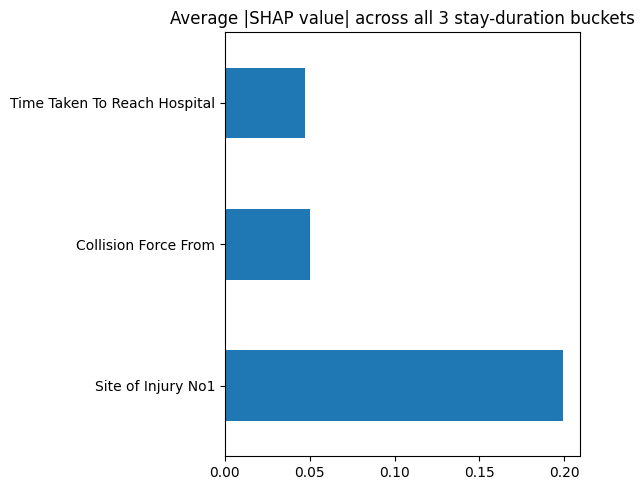

Site of Injury No1              0.199249
Collision Force From            0.050398
Time Taken To Reach Hospital    0.047327
dtype: float64


In [18]:
if FINAL_MODEL_NAME == 'CatBoost':
    explainer = shap.TreeExplainer(final_model)
    X_shap = X_train_enc.copy()
    shap_values = explainer.shap_values(Pool(X_shap, cat_features=cat_idx))
    if isinstance(shap_values, list):
        importance_per_class = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
    else:
        importance_per_class = np.abs(shap_values).mean(axis=(0, 2)) if shap_values.ndim == 3 else np.abs(shap_values).mean(axis=0)
    importance = pd.Series(importance_per_class, index=X_shap.columns).sort_values(ascending=False)
    importance.plot(kind='barh', figsize=(6, 5))
    plt.title('Average |SHAP value| across all 3 stay-duration buckets')
    plt.tight_layout()
    plt.savefig('artifacts/shap_summary.png', dpi=150)
    plt.show()
else:
    pre = final_model.named_steps['pre']
    clf = final_model.named_steps['clf']
    feature_names = pre.get_feature_names_out()
    coefs = pd.Series(np.abs(clf.coef_).mean(axis=0), index=feature_names)
    orig_feature_of = {}
    for fn in feature_names:
        if fn.startswith('num__'):
            orig_feature_of[fn] = fn.replace('num__', '')
        elif fn.startswith('cat__'):
            base = fn.replace('cat__', '')
            for c in CAT_FEATURES:
                if base.startswith(c + '_'):
                    orig_feature_of[fn] = c
                    break
    importance = coefs.groupby(orig_feature_of).sum().sort_values(ascending=False)
    importance.plot(kind='barh', figsize=(6, 5))
    plt.title('Logistic Regression |coefficient| importance (aggregated, averaged over classes)')
    plt.tight_layout()
    plt.savefig('artifacts/feature_importance.png', dpi=150)
    plt.show()

print(importance)

## 11. Final check on the held-out test data

Used exactly once, here, on the model and class-weight balance chosen in Section 9. Nothing above
used this data for any decision.

              precision    recall  f1-score   support

    0-1 days       0.78      0.46      0.58       824
    2-3 days       0.32      0.48      0.39       317
     4+ days       0.11      0.33      0.17        95

    accuracy                           0.46      1236
   macro avg       0.40      0.42      0.38      1236
weighted avg       0.61      0.46      0.50      1236



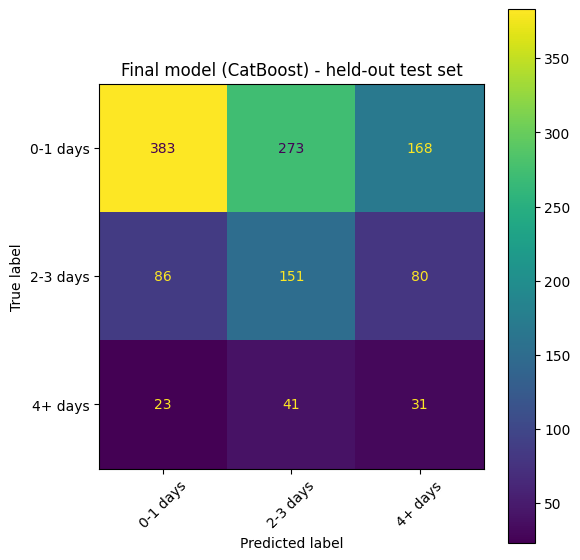


Held-out test recall per bucket: {'0-1 days': np.float64(0.46480582524271846), '2-3 days': np.float64(0.47634069400630913), '4+ days': np.float64(0.3263157894736842)}

Compare recall(4+ days) to the CV estimate from Section 9 - a dramatically lower number
here means overfitting to the training folds, not a reason to re-tune against this test set.


In [19]:
y_pred_test = final_model.predict(X_test_enc)
if hasattr(y_pred_test, 'flatten'):
    y_pred_test = y_pred_test.flatten()

print(classification_report(y_test, y_pred_test))

labels_order = ['0-1 days', '2-3 days', '4+ days']
cm = confusion_matrix(y_test, y_pred_test, labels=labels_order)
disp = ConfusionMatrixDisplay(cm, display_labels=labels_order)
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, xticks_rotation=45)
plt.title(f'Final model ({FINAL_MODEL_NAME}) - held-out test set')
plt.tight_layout()
plt.savefig('artifacts/confusion_matrix_test.png', dpi=150)
plt.show()

test_per_class = dict(zip(sorted(y_test.unique()), recall_score(y_test, y_pred_test, labels=sorted(y_test.unique()), average=None)))
print("\nHeld-out test recall per bucket:", test_per_class)
print("\nCompare recall(4+ days) to the CV estimate from Section 9 - a dramatically lower number")
print("here means overfitting to the training folds, not a reason to re-tune against this test set.")

## 12. A "how sure is this, really" layer

Wraps the finished model for real use. If less than 40% of the features are filled in, the model
refuses to predict. Otherwise it predicts normally, flagged as low-confidence if its own
probability for the top answer is below 60%.

In [20]:
COMPLETENESS_FLOOR = 0.40
LOW_CONF_PROB = 0.60

def predict_with_confidence(record: dict, model=final_model):
    non_missing = sum(1 for f in FEATURES if record.get(f) not in (None, np.nan) and
                       not (isinstance(record.get(f), float) and np.isnan(record.get(f))))
    completeness = non_missing / len(FEATURES)

    if completeness < COMPLETENESS_FLOOR:
        return {'prediction': None, 'probability': None, 'completeness': completeness,
                'status': 'REFUSED - not enough information (under 40% complete)'}

    row = pd.DataFrame([record])[FEATURES]
    for col, order in [('Age', AGE_ORDER), ('Time Taken To Reach Hospital', TIME_ORDER)]:
        if col in row.columns:
            mapping = {v: i for i, v in enumerate(order)}
            row[col] = row[col].map(mapping)
    for c in CAT_FEATURES:
        row[c] = row[c].astype(object).where(row[c].notna(), 'missing').astype(str)

    proba = model.predict_proba(row)[0]
    classes = list(getattr(model, 'classes_', sorted(y_train.unique())))
    pred_idx = int(np.argmax(proba))
    pred_label = classes[pred_idx]
    pred_prob = float(proba[pred_idx])

    status = 'OK' if pred_prob >= LOW_CONF_PROB else 'LOW CONFIDENCE - low model certainty'

    return {'prediction': pred_label, 'probability': round(pred_prob, 3),
            'completeness': round(completeness, 3), 'status': status}

example_full = X_test.iloc[0].to_dict()
example_sparse = {f: None for f in FEATURES}
example_sparse['Age'] = '20-29'

print(predict_with_confidence(example_full))
print(predict_with_confidence(example_sparse))

{'prediction': '4+ days', 'probability': 0.413, 'completeness': 1.0, 'status': 'LOW CONFIDENCE - low model certainty'}
{'prediction': None, 'probability': None, 'completeness': 0.0, 'status': 'REFUSED - not enough information (under 40% complete)'}


## 13. Double-check: does dropping any feature actually help?

Every remaining feature passed the check in Section 4 on its own, but that doesn't rule out one
being unhelpful once combined with the others. Checked directly: retrain with each feature
removed, one at a time, same settings, same class weighting, compared against keeping all of them.

This always retrains with CatBoost specifically, regardless of which model won Section 9 - a
deliberate simplification, consistent with how the transfer probability notebook's ablation was
documented, not an oversight.

In [21]:
def cv_score(cols, params, weights):
    cat_cols_here = [c for c in cols if c in CAT_FEATURES]
    cat_idx_here = [cols.index(c) for c in cat_cols_here]
    classes_sorted = sorted(y_train.unique())

    per_class_recs = {c: [] for c in classes_sorted}
    for tr_idx, val_idx in skf.split(X_train_enc[cols], y_train):
        Xt, Xv = X_train_enc[cols].iloc[tr_idx], X_train_enc[cols].iloc[val_idx]
        yt, yv = y_train.iloc[tr_idx], y_train.iloc[val_idx]
        m = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, loss_function='MultiClass',
                                class_weights=[weights[c] for c in classes_sorted], **params)
        m.fit(Xt, yt, cat_features=cat_idx_here, verbose=0)
        pred = m.predict(Xv).flatten()
        per_class = dict(zip(sorted(yv.unique()), recall_score(yv, pred, labels=sorted(yv.unique()), average=None)))
        for c in per_class_recs:
            per_class_recs[c].append(per_class.get(c, 0))
    return {c: np.mean(v) for c, v in per_class_recs.items()}

baseline_scores = cv_score(FEATURES, best_params, final_weights)
ablation_rows = [{'dropped': '(none - full model)', **{f'recall_{c}': v for c, v in baseline_scores.items()}}]

for f in FEATURES:
    remaining = [c for c in FEATURES if c != f]
    scores = cv_score(remaining, best_params, final_weights)
    ablation_rows.append({'dropped': f, **{f'recall_{c}': v for c, v in scores.items()}})

ablation_df = pd.DataFrame(ablation_rows).sort_values(f'recall_{PRIMARY_CLASS}', ascending=False)
ablation_df

,dropped,recall_0-1 days,recall_2-3 days,recall_4+ days
1,Time Taken To Reach Hospital,0.394729,0.302755,0.551181
0,(none - full model),0.426596,0.331256,0.498688
2,Collision Force From,0.498177,0.285441,0.467192
3,Site of Injury No1,0.263685,0.403215,0.454068


## 14. Save and document

In [22]:
if FINAL_MODEL_NAME == 'CatBoost':
    final_model.save_model('artifacts/stay_duration_model_catboost.cbm')
else:
    joblib.dump(final_model, 'artifacts/stay_duration_model.joblib')

importance.to_csv('artifacts/feature_importance.csv')

summary = {
    'final_model': FINAL_MODEL_NAME,
    'stay_duration_buckets': ['0-1 days', '2-3 days', '4+ days'],
    'candidate_features': CANDIDATE_FEATURES,
    'features_dropped_after_validation': features_to_drop,
    'final_features_used': FEATURES,
    'primary_class_weight_multiplier': float(WEIGHT_MULTIPLIER),
    'other_class_recall_floor_used_for_selection': OTHER_CLASS_RECALL_FLOOR,
    'cv_at_chosen_weights': {k: float(v) for k, v in winner.items() if k.startswith('recall_')},
    'held_out_test_recall_per_bucket': {k: float(v) for k, v in test_per_class.items()},
    'notes': [
        "Loaded from Preprocessed Dataset.csv (pre-severity-label dataset) so severity_label/composite could not be included as features - severity's length-of-stay component IS total_days, the value this model buckets and predicts, so using it would be near-direct leakage.",
        "Stay-duration buckets merged from an initial 4 groups to 3 (0-1 days 66.7%, 2-3 days 25.6%, 4+ days 7.7%) - 0 and 1 day were the hardest to tell apart and mean the same thing practically (early discharge), a decision made before evaluating model performance.",
        "Type of injury No 1, Investigation Done, and Current Hospital Name excluded - not available at arrival, or risk hospital-identity leakage.",
        f"Dropped {features_to_drop} after train-only chi-square/Cramer's V or Kruskal-Wallis validation.",
        f"Rare categories (< {RARE_CATEGORY_MIN_COUNT} training rows) consolidated into 'Other', fit on train only.",
        "3-class imbalance handled via class weighting, with an extra weight multiplier on the '4+ days' bucket chosen via a guarded sweep (every other bucket must keep >= 35% recall).",
        "3-fold CV and trimmed hyperparameter search used throughout, a disclosed compute tradeoff consistent with the discharge outcome notebook."
    ]
}
with open('artifacts/model_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))

{
  "final_model": "CatBoost",
  "stay_duration_buckets": [
    "0-1 days",
    "2-3 days",
    "4+ days"
  ],
  "candidate_features": [
    "Age",
    "Gender",
    "Mode of Transport to the Hospital",
    "Time Taken To Reach Hospital",
    "Vehicle Type",
    "Helmet Worn",
    "Collision With",
    "Approximate Speed",
    "Road Type",
    "Road Condition",
    "Visiblity",
    "Road Signals Exist",
    "Collision Force From",
    "Alcohol Consumption",
    "Illicit Drugs",
    "Site of Injury No1"
  ],
  "features_dropped_after_validation": [
    "Gender",
    "Mode of Transport to the Hospital",
    "Vehicle Type",
    "Helmet Worn",
    "Collision With",
    "Approximate Speed",
    "Road Type",
    "Road Condition",
    "Visiblity",
    "Road Signals Exist",
    "Alcohol Consumption",
    "Illicit Drugs",
    "Age"
  ],
  "final_features_used": [
    "Time Taken To Reach Hospital",
    "Collision Force From",
    "Site of Injury No1"
  ],
  "primary_class_weight_multiplier": 1.